In [11]:
# ============================================================
# 02 — EXPLORATORY DATA ANALYSIS (EDA)
# Gas Turbine Energy Yield and Emissions
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)

# Update this path if your project folder is structured differently
DATA_DIR = Path("../data")

files = sorted(DATA_DIR.glob("gt_*.csv"))

if not files:
    raise FileNotFoundError(
        f"No gt_*.csv files found in {DATA_DIR.resolve()}. "
        "Check DATA_DIR."
    )

frames = []

for file in files:
    df = pd.read_csv(file)
    year = int(file.stem.split("_")[-1])
    df["Year"] = year
    df["Row_In_Year"] = np.arange(len(df))
    frames.append(df)

data = pd.concat(frames, ignore_index=True)

# Original measurement columns
feature_cols = [
    "AT", "AP", "AH", "AFDP",
    "GTEP", "TIT", "TAT", "CDP"
]

target_cols = ["TEY", "CO", "NOX"]
measurement_cols = feature_cols + target_cols

# Validate expected columns
missing_cols = set(measurement_cols) - set(data.columns)

if missing_cols:
    raise ValueError(f"Missing expected columns: {missing_cols}")

print("Dataset shape:", data.shape)
print("Years:", sorted(data["Year"].unique()))
display(data.head())

Dataset shape: (36733, 13)
Years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015)]


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,Year,Row_In_Year
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011,0
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011,1
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011,2
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011,3
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011,4


In [12]:
print("========== DATASET OVERVIEW ==========")
print(f"Observations: {len(data):,}")
print(f"Measurement variables: {len(measurement_cols)}")
print(f"Years: {sorted(data['Year'].unique())}")

print("\nObservations per year:")
display(data.groupby("Year").size().rename("Observations").to_frame())

print("\nDescriptive statistics:")
display(data[measurement_cols].describe().T)

========== DATASET OVERVIEW ==========
Observations: 36,733
Measurement variables: 11
Years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015)]

Observations per year:


,Observations
Year,
2011,7411
2012,7628
2013,7152
2014,7158
2015,7384



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
AT,36733.0,17.712726,7.447451,-6.234800,11.7810,17.8010,23.6650,37.1030
AP,36733.0,1013.070165,6.463346,985.850000,1008.8000,1012.6000,1017.0000,1036.6000
AH,36733.0,77.867015,14.461355,24.085000,68.1880,80.4700,89.3760,100.2000
AFDP,36733.0,3.925518,0.773936,2.087400,3.3556,3.9377,4.3769,7.6106
GTEP,36733.0,25.563801,4.195957,17.698000,23.1290,25.1040,29.0610,40.7160
TIT,36733.0,1081.428084,17.536373,1000.800000,1071.8000,1085.9000,1097.0000,1100.9000
TAT,36733.0,546.158517,6.842360,511.040000,544.7200,549.8800,550.0400,550.6100
CDP,36733.0,12.060525,1.088795,9.851800,11.4350,11.9650,12.8550,15.1590
TEY,36733.0,133.506404,15.618634,100.020000,124.4500,133.7300,144.0800,179.5000
CO,36733.0,2.372468,2.262672,0.000388,1.1824,1.7135,2.8429,44.1030


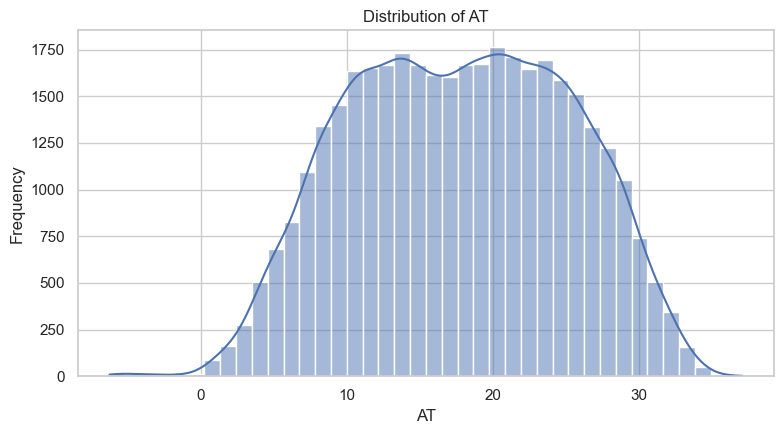

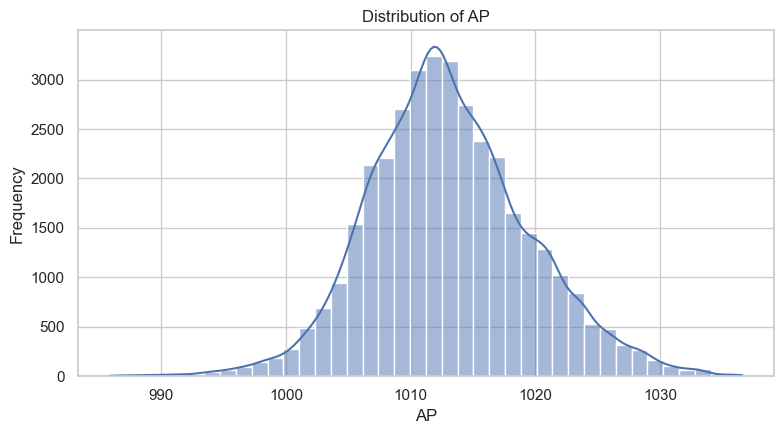

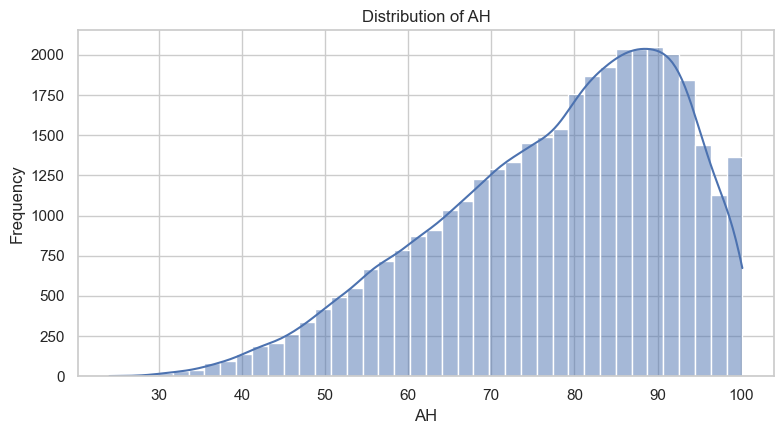

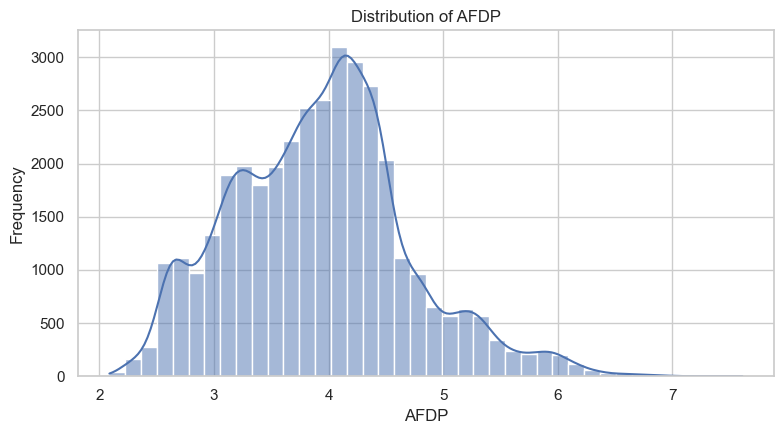

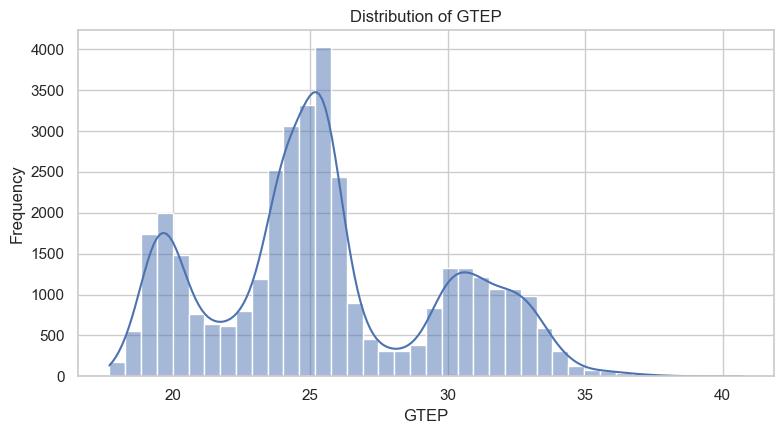

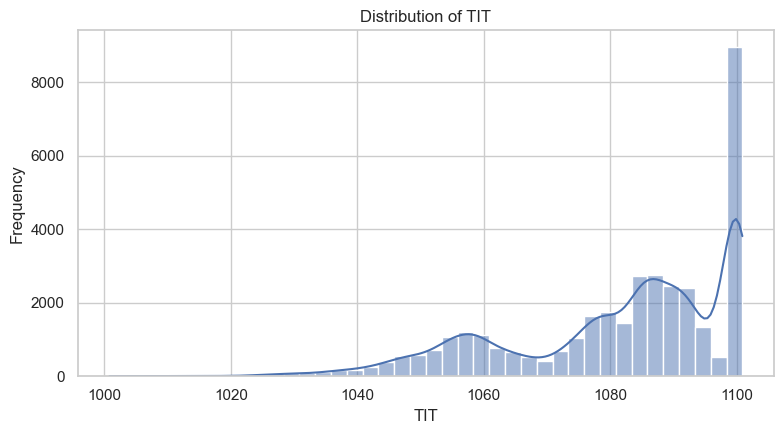

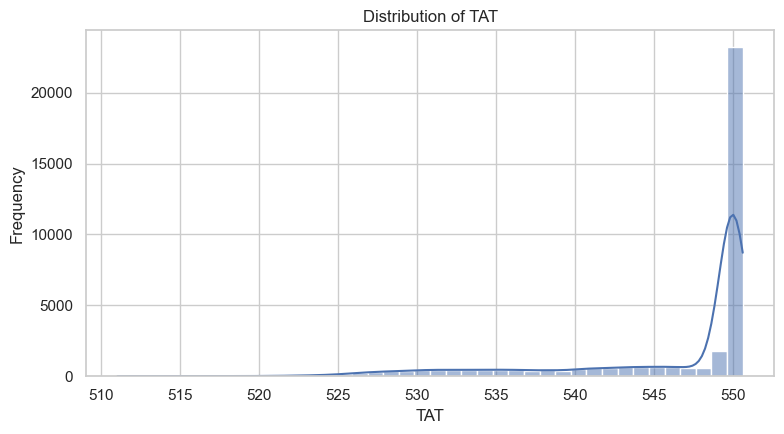

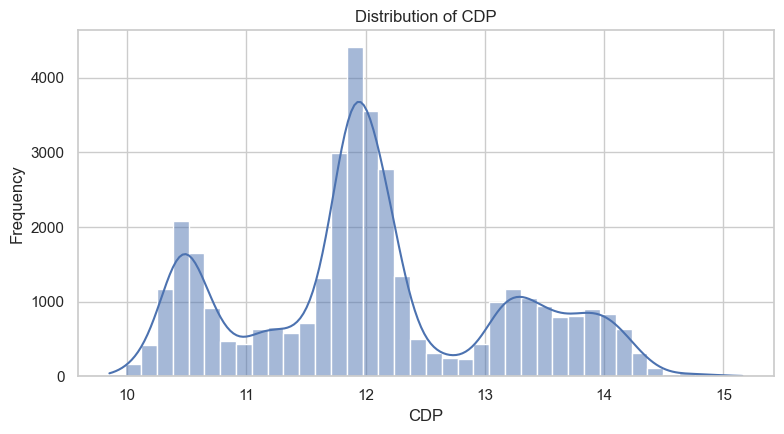

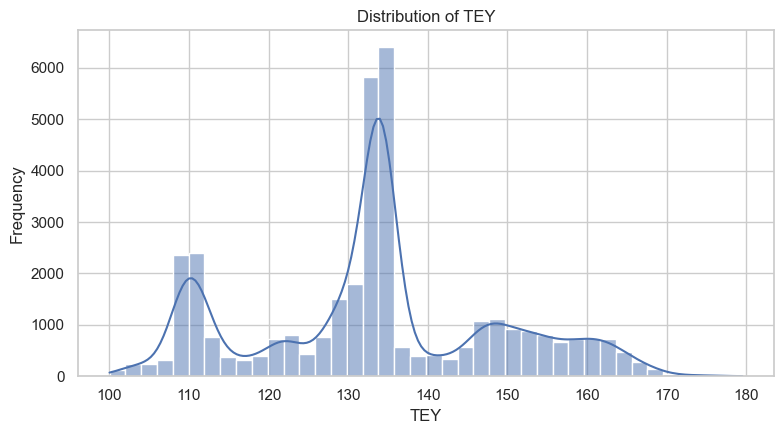

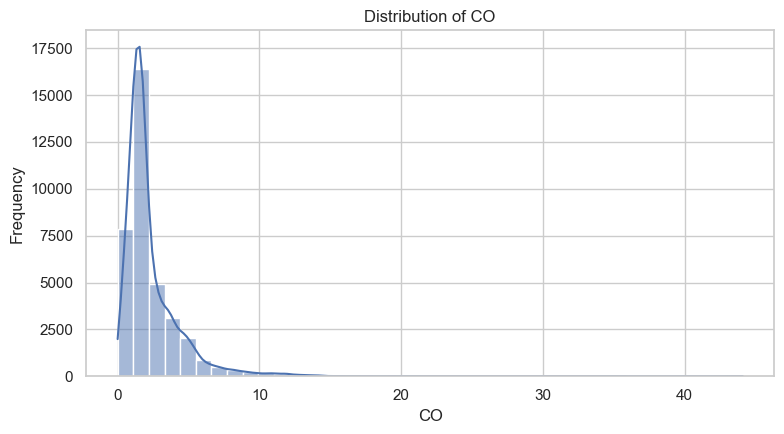

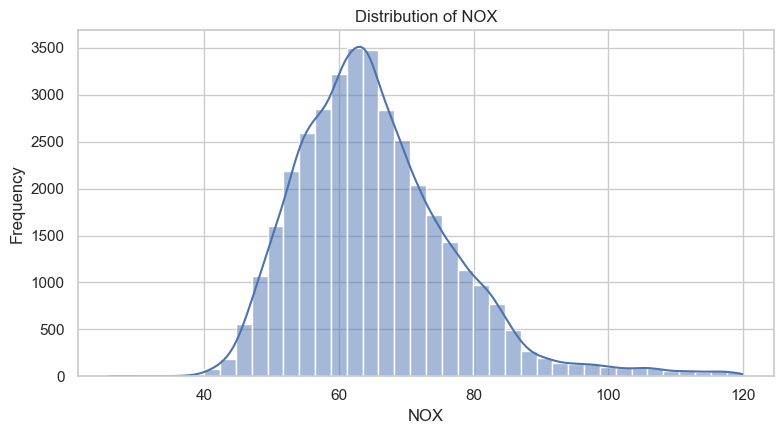

In [13]:
# Histograms and density curves for all measurements

for col in measurement_cols:
    fig, ax = plt.subplots(figsize=(8, 4.5))

    sns.histplot(
        data=data,
        x=col,
        kde=True,
        bins=40,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()

In [14]:
distribution_stats = data[measurement_cols].agg(
    ["mean", "median", "std", "min", "max", "skew"]
).T

distribution_stats["IQR"] = (
    data[measurement_cols].quantile(0.75)
    - data[measurement_cols].quantile(0.25)
)

display(distribution_stats.round(4))

,mean,median,std,min,max,skew,IQR
AT,17.7127,17.8010,7.4475,-6.2348,37.1030,-0.0435,11.8840
AP,1013.0702,1012.6000,6.4633,985.8500,1036.6000,0.1941,8.2000
AH,77.8670,80.4700,14.4614,24.0850,100.2000,-0.6280,21.1880
AFDP,3.9255,3.9377,0.7739,2.0874,7.6106,0.3811,1.0213
GTEP,25.5638,25.1040,4.1960,17.6980,40.7160,0.3290,5.9320
TIT,1081.4281,1085.9000,17.5364,1000.8000,1100.9000,-0.8883,25.2000
TAT,546.1585,549.8800,6.8424,511.0400,550.6100,-1.7559,5.3200
CDP,12.0605,11.9650,1.0888,9.8518,15.1590,0.2368,1.4200
TEY,133.5064,133.7300,15.6186,100.0200,179.5000,0.1166,19.6300
CO,2.3725,1.7135,2.2627,0.0004,44.1030,4.8382,1.6605


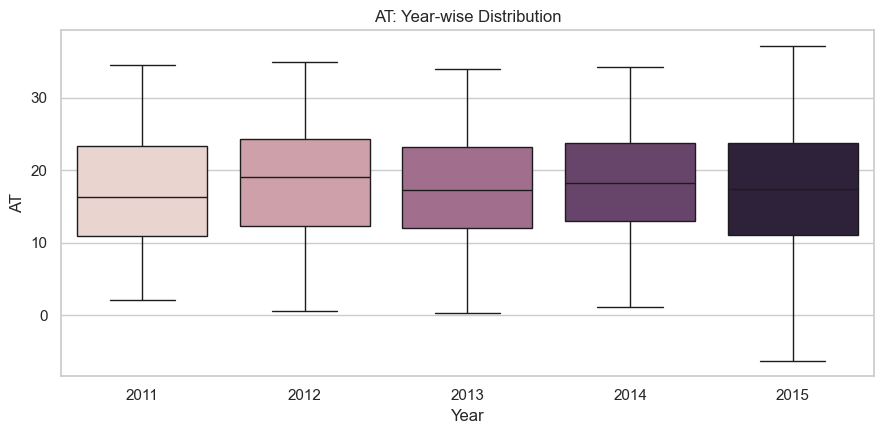

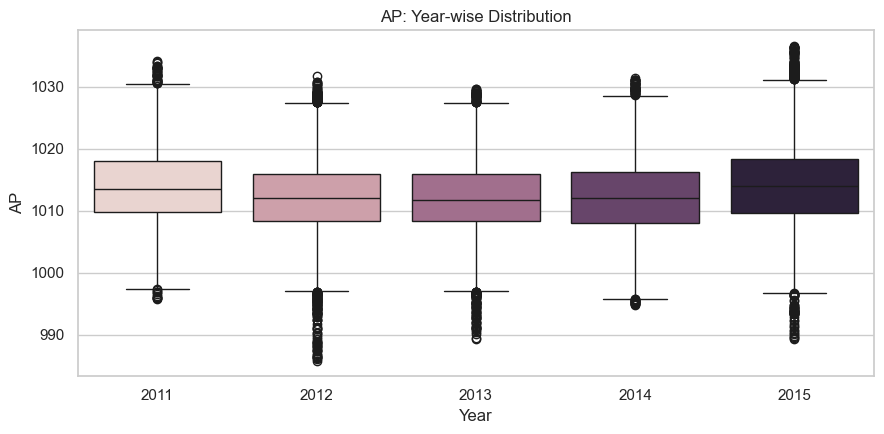

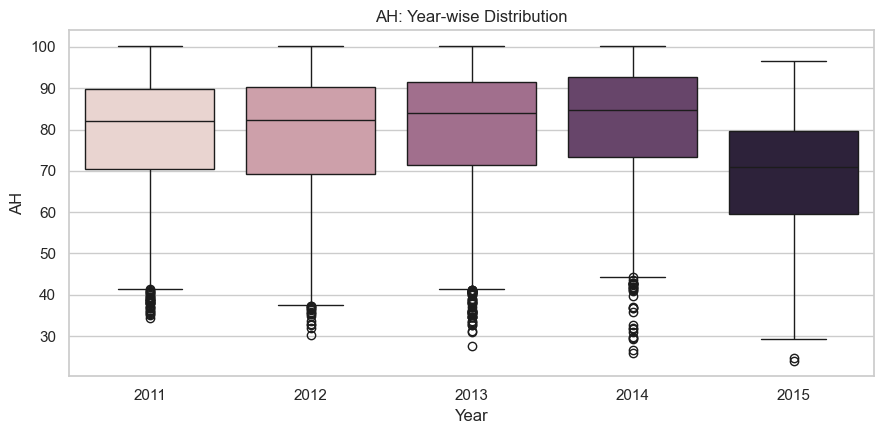

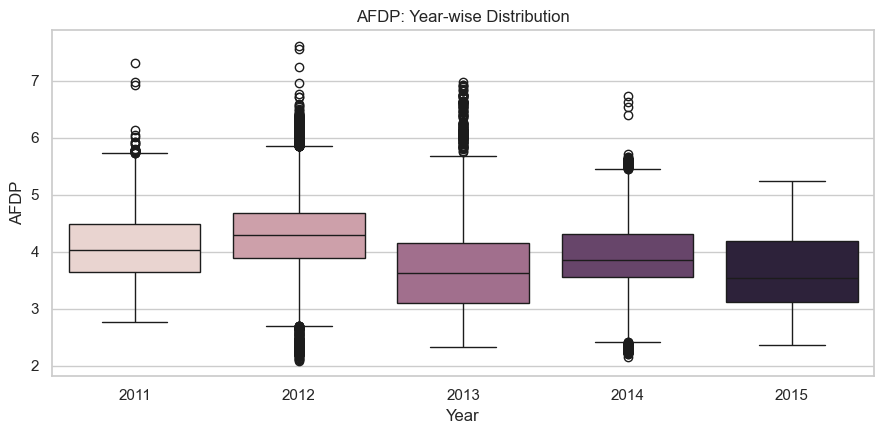

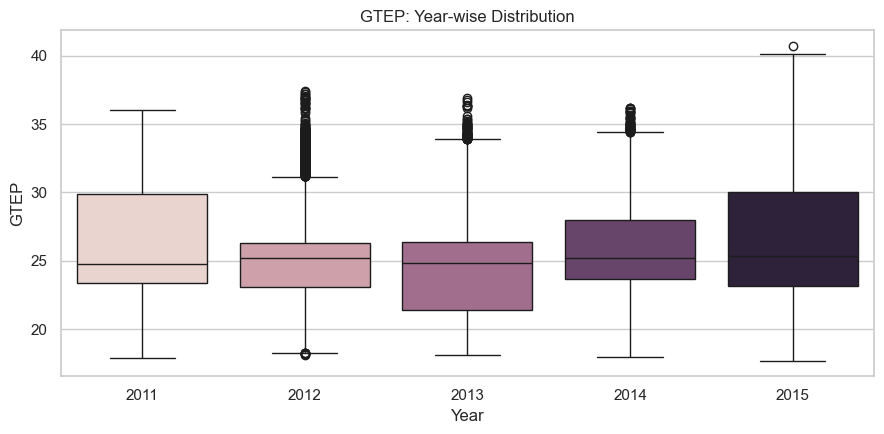

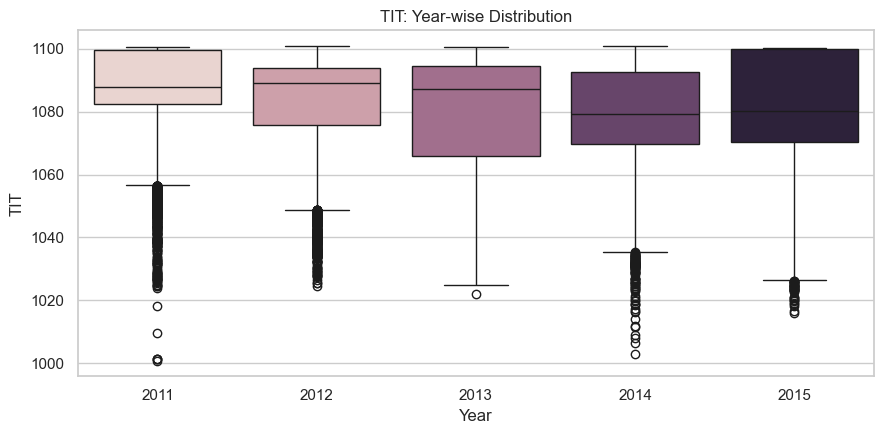

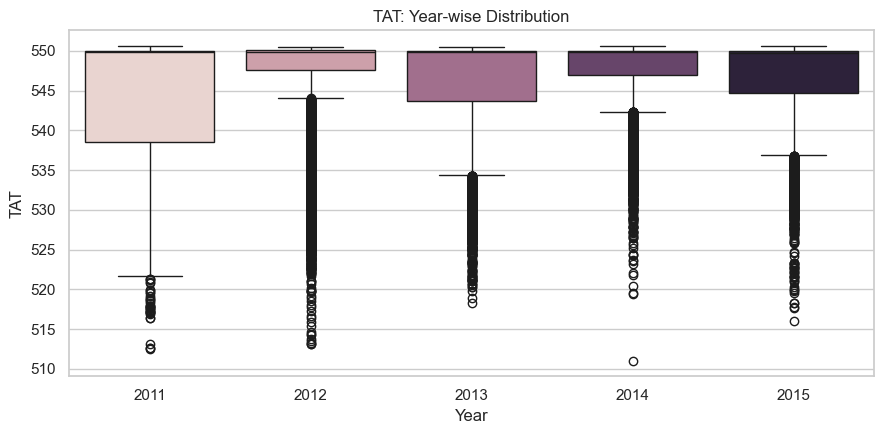

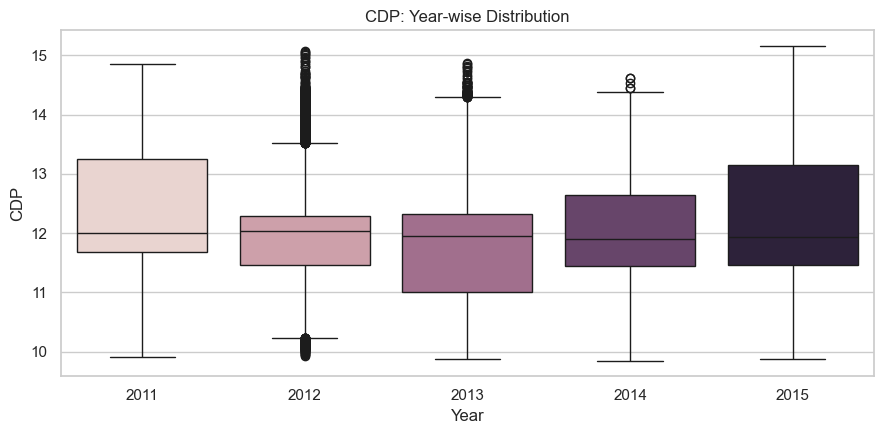

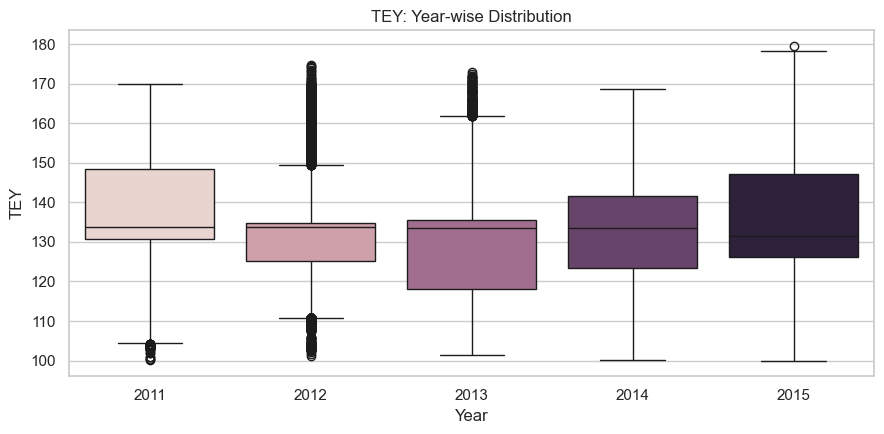

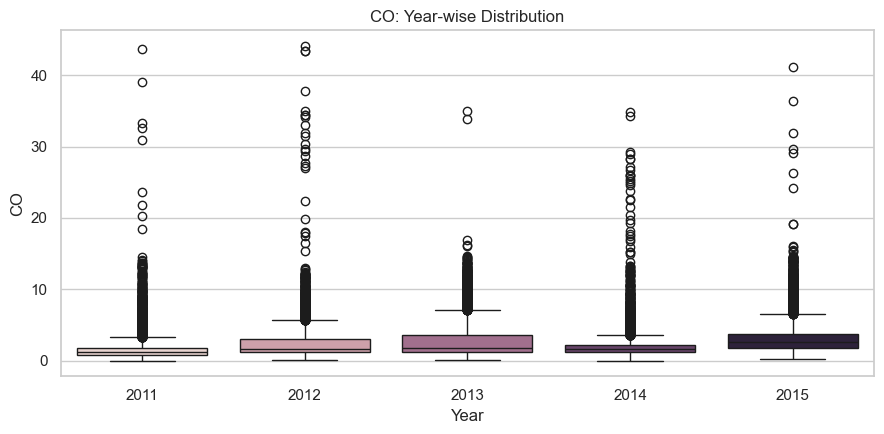

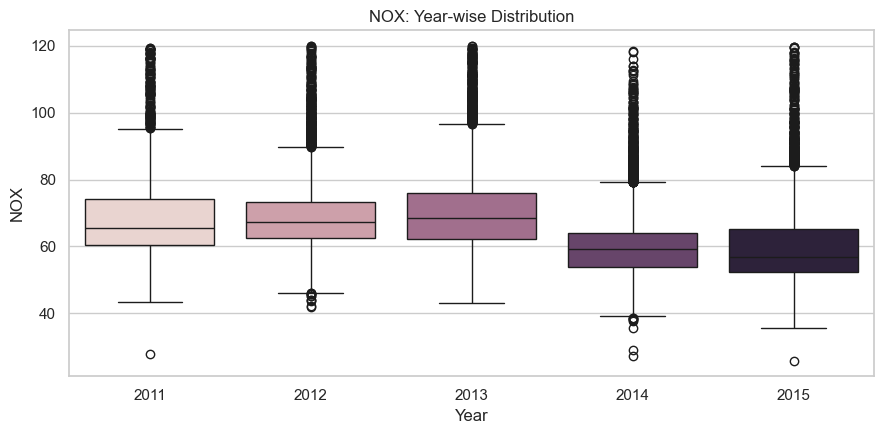

In [15]:
# Boxplots by year reveal changes in spread and central tendency

for col in measurement_cols:
    fig, ax = plt.subplots(figsize=(9, 4.5))

    sns.boxplot(
        data=data,
        x="Year",
        y=col,
        hue="Year",
        legend=False,
        ax=ax
    )

    ax.set_title(f"{col}: Year-wise Distribution")
    ax.set_xlabel("Year")
    ax.set_ylabel(col)

    plt.tight_layout()
    plt.show()

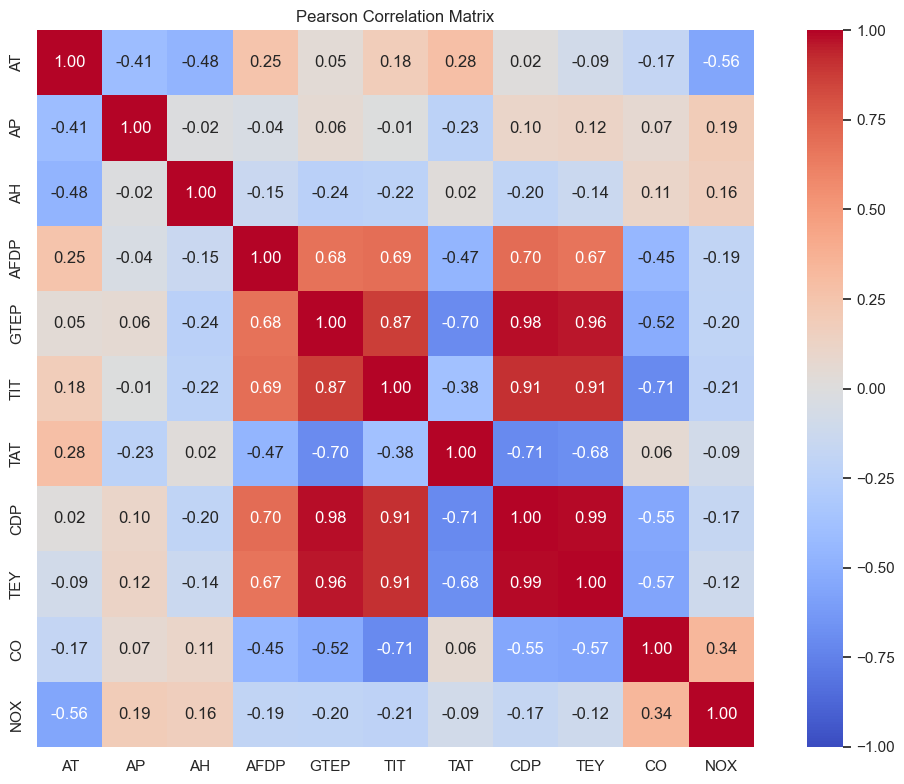

In [16]:
corr = data[measurement_cols].corr(method="pearson")

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

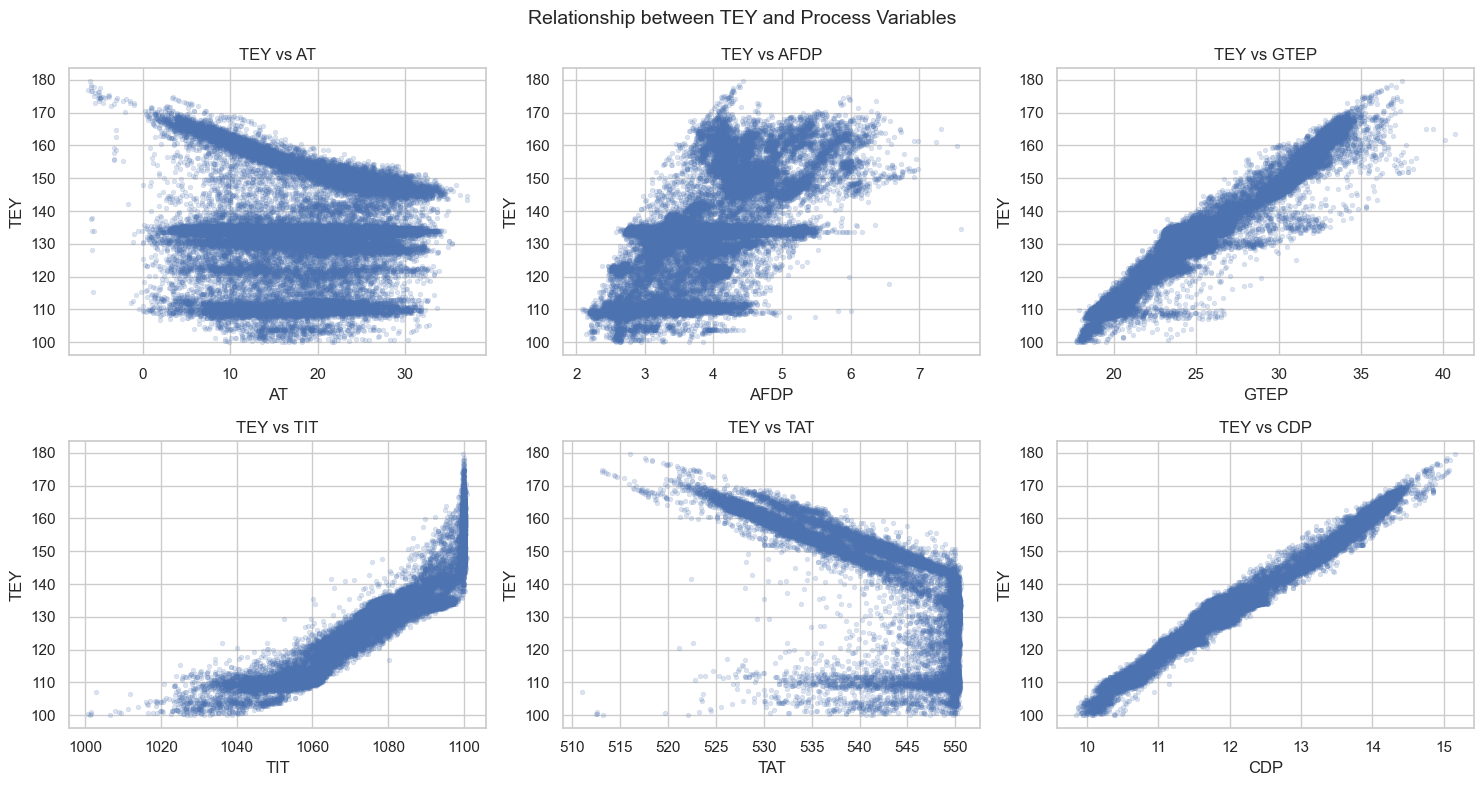

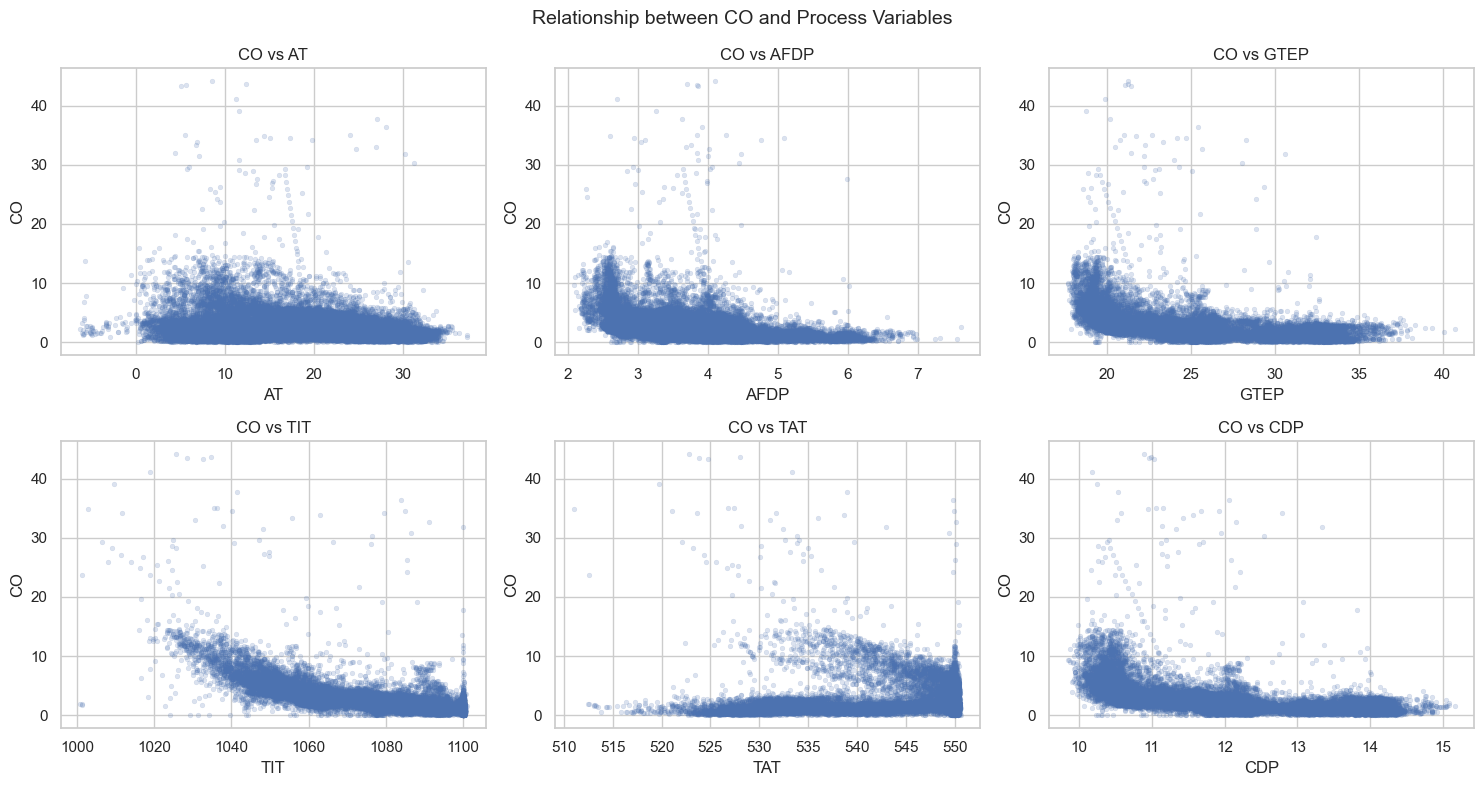

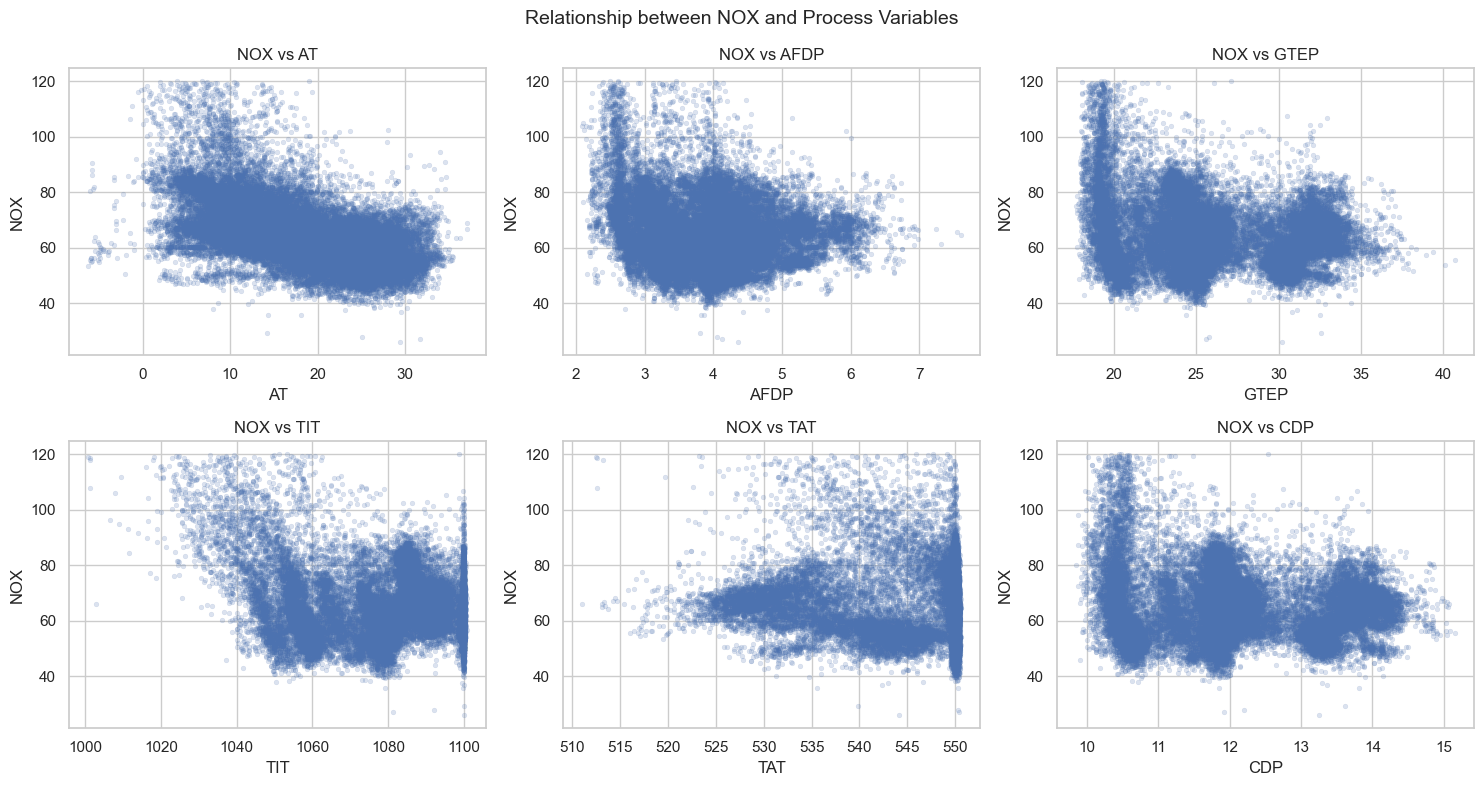

In [17]:
selected_features = ["AT", "AFDP", "GTEP", "TIT", "TAT", "CDP"]

for target in target_cols:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()

    for ax, feature in zip(axes, selected_features):
        sns.scatterplot(
            data=data,
            x=feature,
            y=target,
            alpha=0.20,
            s=12,
            edgecolor=None,
            ax=ax
        )

        ax.set_title(f"{target} vs {feature}")

    fig.suptitle(
        f"Relationship between {target} and Process Variables",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

TEY                     CO                   NOX                
         mean  median     std   mean median    std    mean  median     std
Year                                                                      
2011  135.746  133.81  16.209  1.572  1.156  1.845  67.575  65.542  10.683
2012  132.676  133.76  15.302  2.361  1.636  2.474  68.789  67.246  10.225
2013  132.168  133.57  16.348  2.723  1.783  2.364  70.008  68.651  12.048
2014  132.908  133.42  13.603  2.081  1.655  2.007  60.067  59.278   9.972
2015  133.993  131.60  16.179  3.130  2.533  2.235  59.891  56.838  11.132

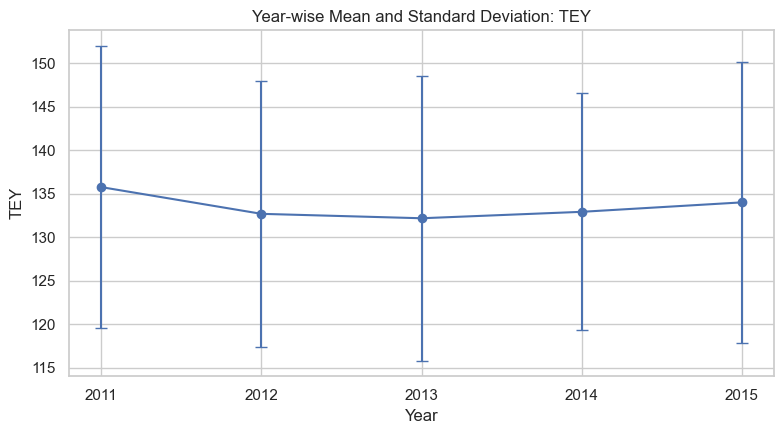

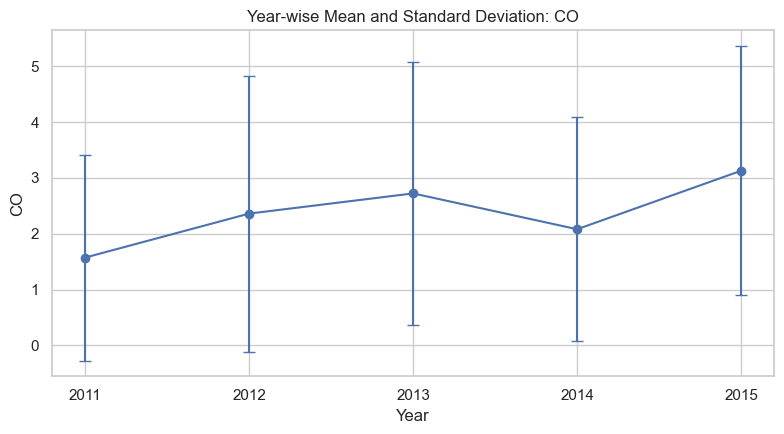

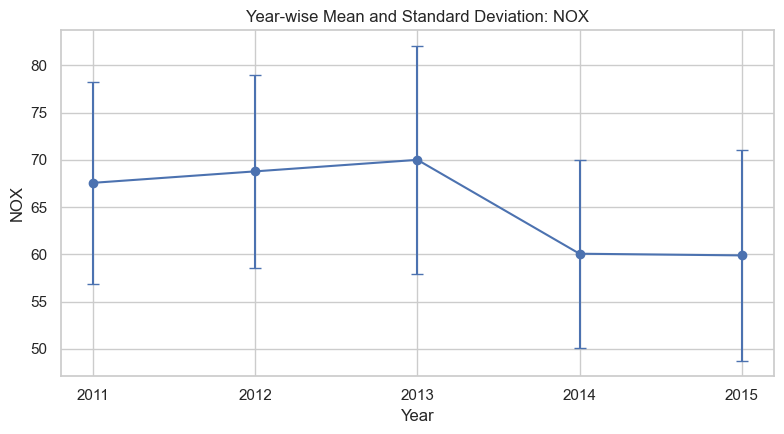

In [18]:
yearly_targets = data.groupby("Year")[target_cols].agg(
    ["mean", "median", "std"]
)

display(yearly_targets.round(3))

for target in target_cols:
    yearly_mean = data.groupby("Year")[target].mean()
    yearly_std = data.groupby("Year")[target].std()

    fig, ax = plt.subplots(figsize=(8, 4.5))

    ax.errorbar(
        yearly_mean.index,
        yearly_mean.values,
        yerr=yearly_std.values,
        fmt="o-",
        capsize=4
    )

    ax.set_title(f"Year-wise Mean and Standard Deviation: {target}")
    ax.set_xlabel("Year")
    ax.set_ylabel(target)
    ax.set_xticks(yearly_mean.index)

    plt.tight_layout()
    plt.show()

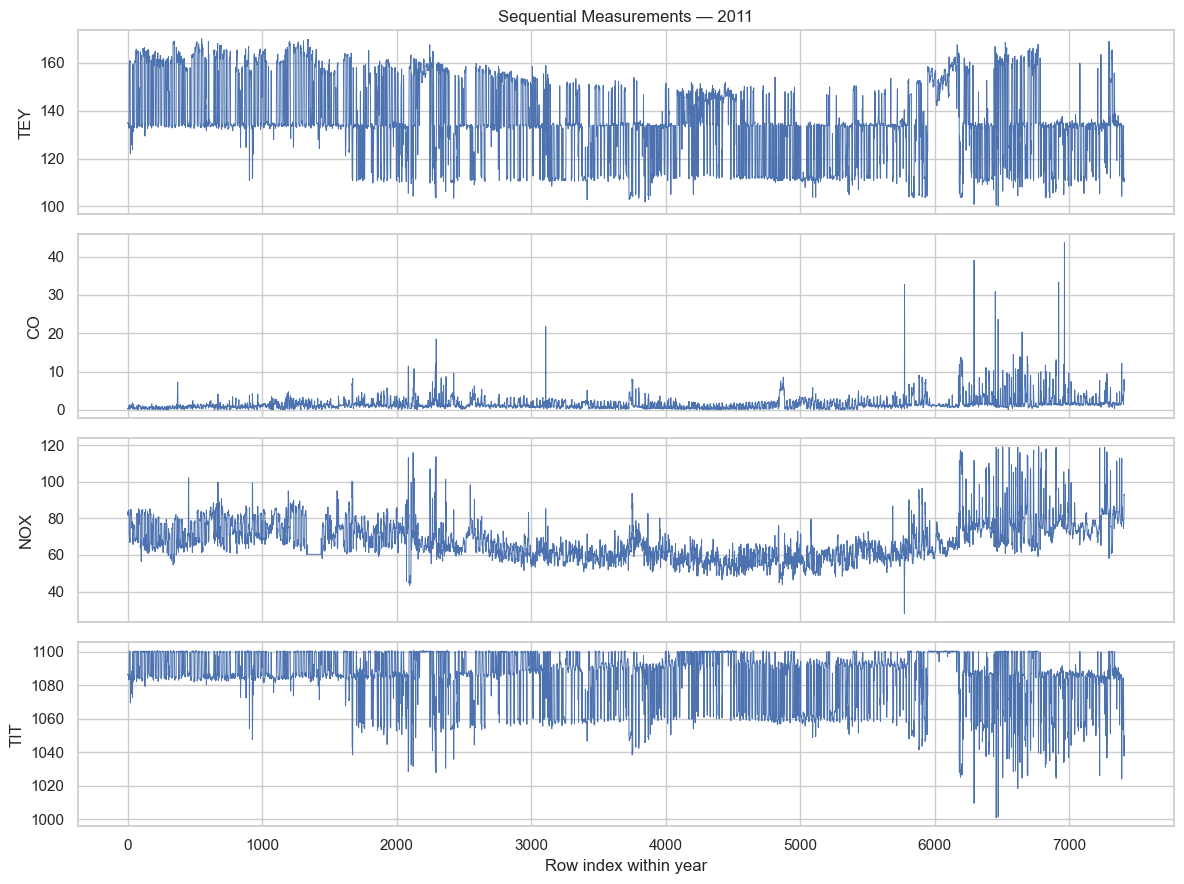

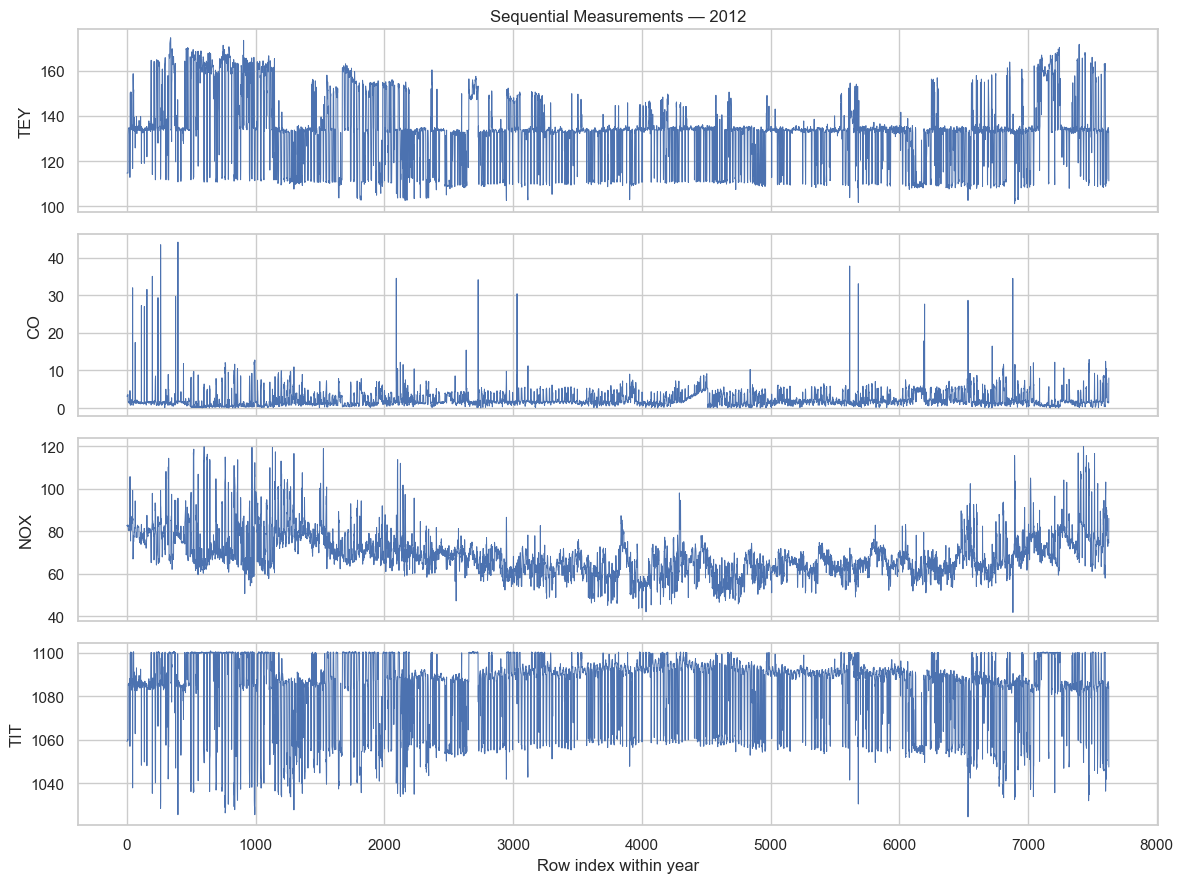

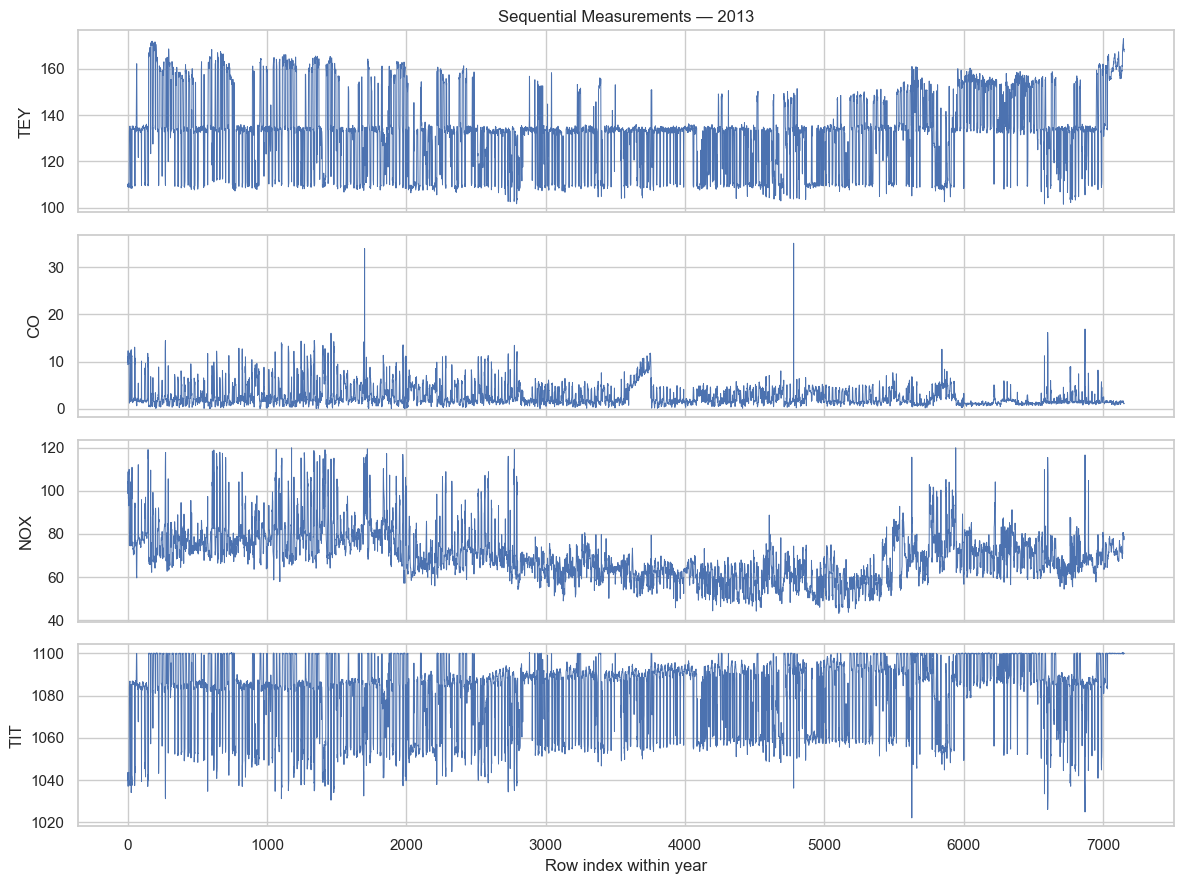

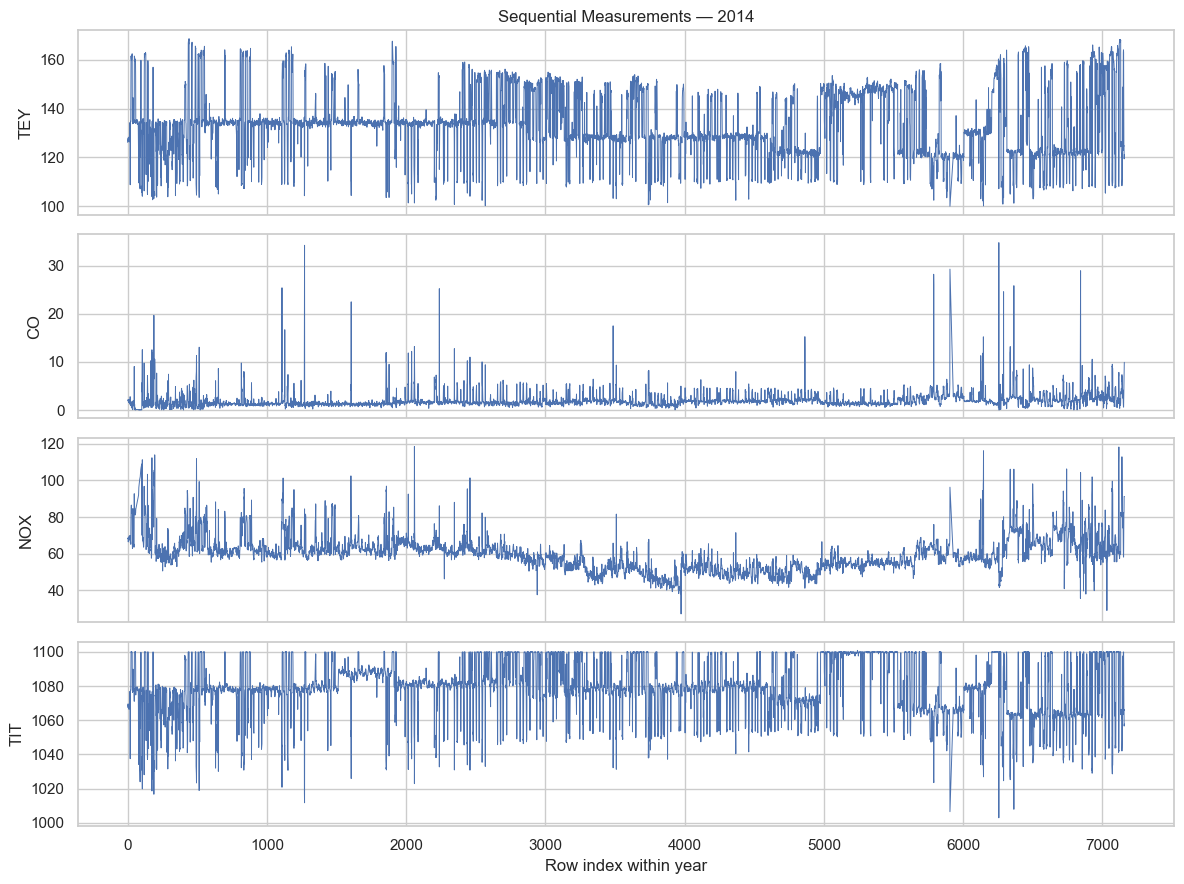

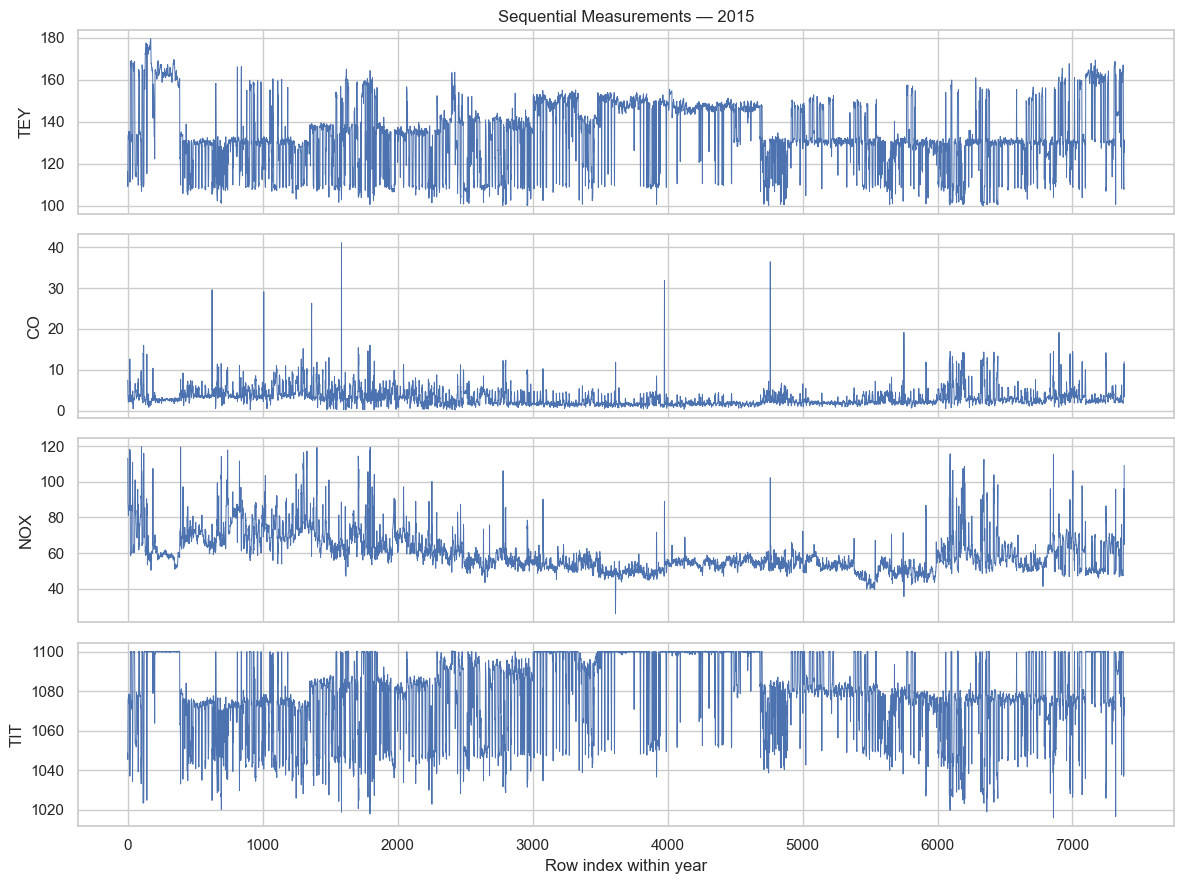

In [19]:
# Plot selected variables in their original within-year row order

selected_series = ["TEY", "CO", "NOX", "TIT"]

for year in sorted(data["Year"].unique()):
    year_df = data[data["Year"] == year]

    fig, axes = plt.subplots(
        len(selected_series), 1,
        figsize=(12, 9),
        sharex=True
    )

    for ax, col in zip(axes, selected_series):
        ax.plot(
            year_df["Row_In_Year"],
            year_df[col],
            linewidth=0.7
        )

        ax.set_ylabel(col)

    axes[0].set_title(f"Sequential Measurements — {year}")
    axes[-1].set_xlabel("Row index within year")

    plt.tight_layout()
    plt.show()

,Year_2011,Year_2012,Year_2013,Year_2014,Year_2015
AT,0.993,0.993,0.992,0.992,0.992
AP,0.998,0.997,0.998,0.995,0.998
AH,0.950,0.957,0.957,0.950,0.950
AFDP,0.872,0.923,0.926,0.917,0.899
GTEP,0.839,0.847,0.861,0.836,0.886
TIT,0.802,0.813,0.825,0.823,0.843
TAT,0.817,0.855,0.848,0.793,0.865
CDP,0.854,0.852,0.861,0.833,0.874
TEY,0.850,0.850,0.861,0.830,0.863
CO,0.553,0.525,0.773,0.647,0.668


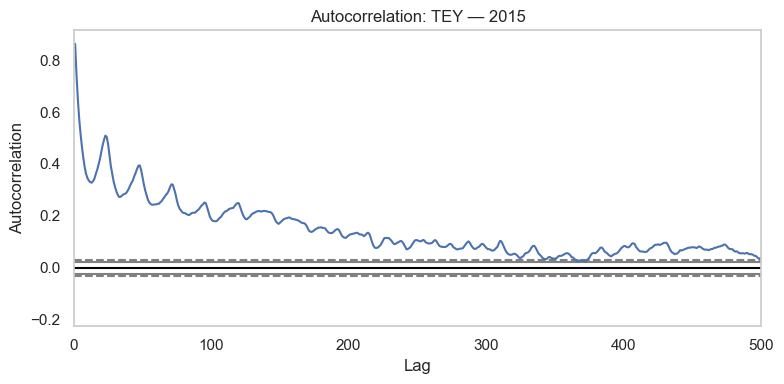

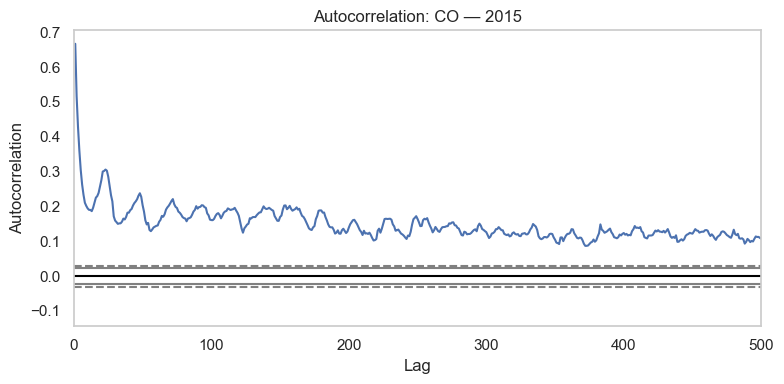

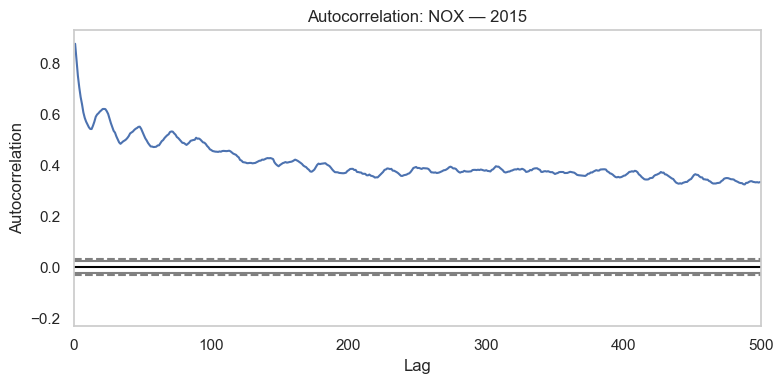

In [21]:
# Lag-1 autocorrelation, calculated separately for each year
from pandas.plotting import autocorrelation_plot

lag1_results = {}

for col in measurement_cols:
    lag1_results[col] = {
        year: group[col].autocorr(lag=1)
        for year, group in data.groupby("Year", sort=True)
    }

lag1_table = pd.DataFrame(lag1_results).T
lag1_table.columns = [
    f"Year_{year}" for year in lag1_table.columns
]

display(lag1_table.round(3))


for col in ["TEY", "CO", "NOX"]:
    year_df = data[data["Year"] == 2015]

    fig, ax = plt.subplots(figsize=(8, 4))

    autocorrelation_plot(year_df[col], ax=ax)

    ax.set_title(f"Autocorrelation: {col} — 2015")
    ax.set_xlim(0, min(500, len(year_df)))

    plt.tight_layout()
    plt.show()

In [22]:
train_period = data[data["Year"] <= 2014]
test_period = data[data["Year"] == 2015]

range_comparison = pd.DataFrame({
    "Train_Min": train_period[measurement_cols].min(),
    "Train_Max": train_period[measurement_cols].max(),
    "Test_Min": test_period[measurement_cols].min(),
    "Test_Max": test_period[measurement_cols].max()
})

range_comparison["Below_Train_Range_%"] = (
    test_period[measurement_cols]
    .lt(train_period[measurement_cols].min())
    .mean() * 100
)

range_comparison["Above_Train_Range_%"] = (
    test_period[measurement_cols]
    .gt(train_period[measurement_cols].max())
    .mean() * 100
)

display(range_comparison.round(3))

,Train_Min,Train_Max,Test_Min,Test_Max,Below_Train_Range_%,Above_Train_Range_%
AT,0.290,34.929,-6.235,37.103,0.962,0.163
AP,985.850,1034.200,989.400,1036.600,0.000,0.393
AH,25.987,100.200,24.085,96.666,0.027,0.000
AFDP,2.087,7.611,2.369,5.240,0.000,0.000
GTEP,17.878,37.402,17.698,40.716,0.122,0.230
TIT,1000.800,1100.900,1016.000,1100.400,0.000,0.000
TAT,511.040,550.610,516.040,550.590,0.000,0.000
CDP,9.852,15.081,9.871,15.159,0.000,0.027
TEY,100.030,174.610,100.020,179.500,0.014,0.257
CO,0.000,44.103,0.213,41.097,0.000,0.000


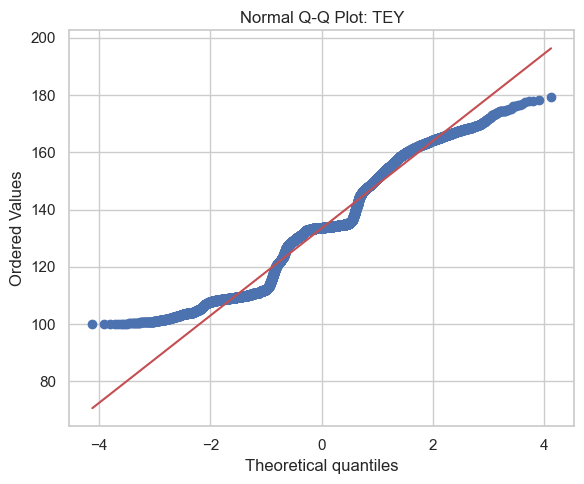

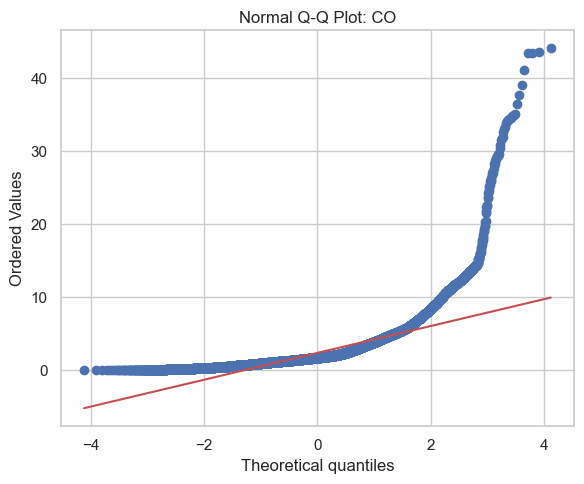

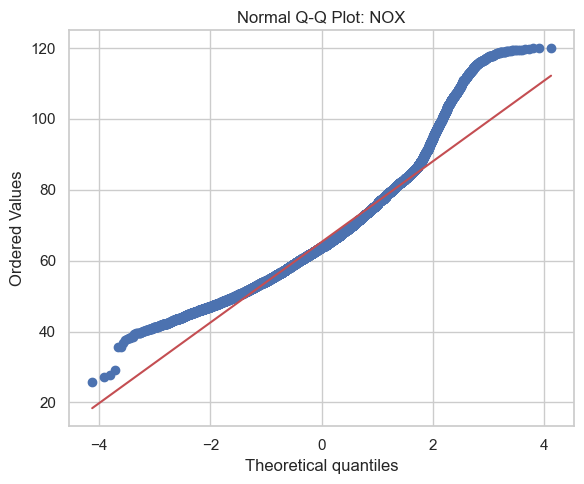

In [23]:
from scipy import stats

for target in target_cols:
    fig, ax = plt.subplots(figsize=(6, 5))

    stats.probplot(
        data[target].dropna(),
        dist="norm",
        plot=ax
    )

    ax.set_title(f"Normal Q-Q Plot: {target}")
    plt.tight_layout()
    plt.show()

In [24]:
# Create an output directory
OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save numerical summaries
distribution_stats.to_csv(
    OUTPUT_DIR / "eda_distribution_statistics.csv"
)

corr.to_csv(
    OUTPUT_DIR / "eda_correlation_matrix.csv"
)

lag1_table.to_csv(
    OUTPUT_DIR / "eda_lag1_autocorrelation.csv"
)

range_comparison.to_csv(
    OUTPUT_DIR / "eda_2015_range_comparison.csv"
)

print("EDA tables saved to:", OUTPUT_DIR.resolve())

EDA tables saved to: C:\Users\devra\Music\gas-turbine-ml\outputs
